# Confidence analysis
## Setup — full test split, top-class confidence, no calibration fitting

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.99, 10
model_names = ['resnet18', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')

3421 test images; high-confidence threshold: 99%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=95.79%, mean confidence=98.71%, ECE=0.0302
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


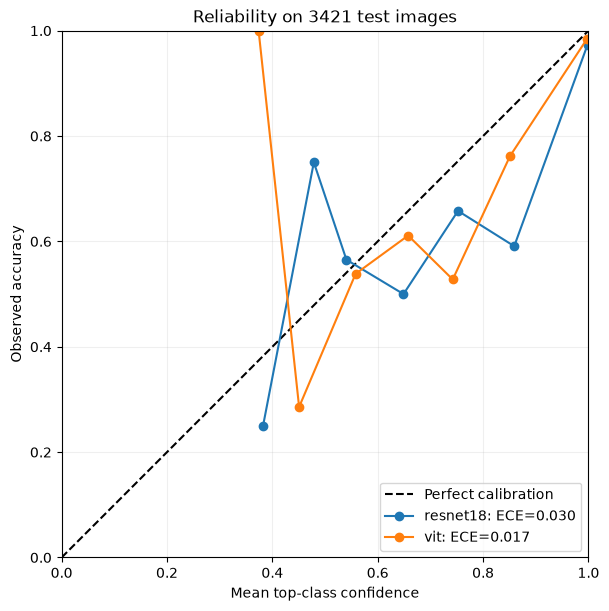

In [2]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## Confidence distributions — one stacked chart per model, for correct and incorrect images separately; stacks show true class

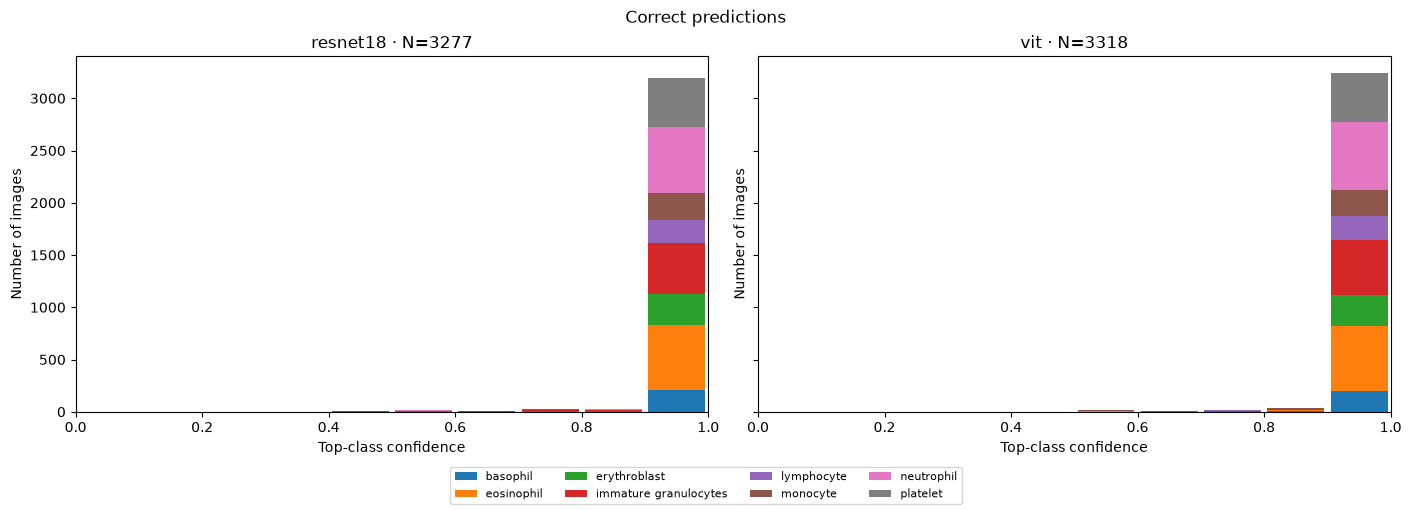

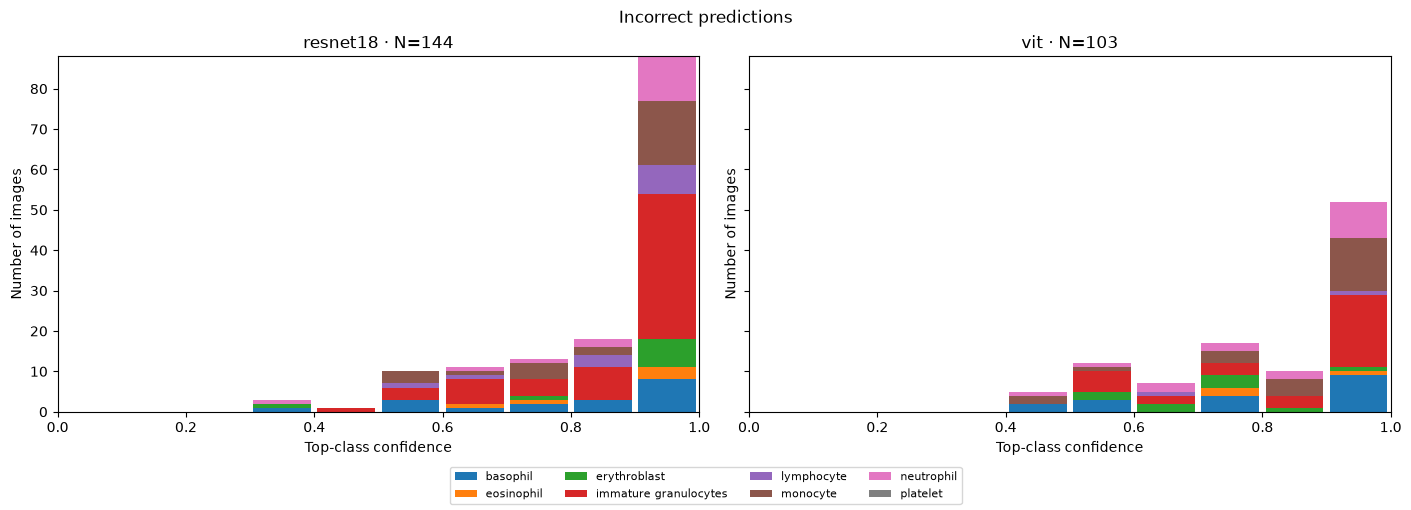

In [3]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, layout='constrained')
    for m, ax in enumerate(axes):
        bottom = np.zeros(n_bins)
        for c, class_name in enumerate(class_names):
            mask = (correct[m] == is_correct) & (labels == c)
            counts = np.histogram(confidence[m, mask], bins=bins)[0]
            ax.bar(centers, counts, width=0.09, bottom=bottom, color=f'C{c}', label=class_name)
            bottom += counts
        ax.set(title=f'{model_names[m]} · N={(correct[m] == is_correct).sum()}',
               xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='outside lower center', ncol=4, fontsize=8)
    fig.suptitle(title)
    plt.show()

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

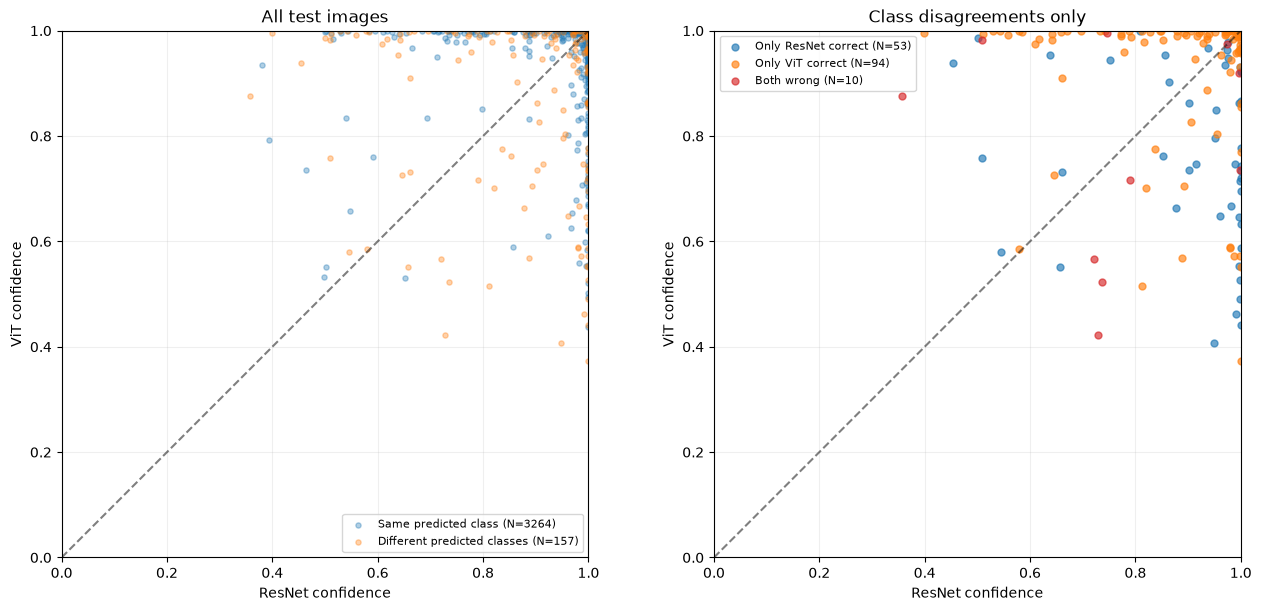

In [4]:
agree = predicted[0] == predicted[1]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
    axes[0].scatter(confidence[0, mask], confidence[1, mask], s=14, alpha=0.35,
                    color=color, label=f'{title} (N={mask.sum()})')
groups = [(correct[0] & ~correct[1], 'C0', 'Only ResNet correct'),
          (~correct[0] & correct[1], 'C1', 'Only ViT correct'),
          (~correct[0] & ~correct[1], 'C3', 'Both wrong')]
for mask, color, title in groups:
    mask = mask & ~agree
    axes[1].scatter(confidence[0, mask], confidence[1, mask], s=25, alpha=0.65,
                    color=color, label=f'{title} (N={mask.sum()})')
for ax, title in zip(axes, ['All test images', 'Class disagreements only']):
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    ax.set(title=title, xlabel='ResNet confidence', ylabel='ViT confidence', xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect('equal')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

## Predictive entropy — normalized to [0, 1]; correct/error distributions and empirical error rate by entropy bin, with image counts

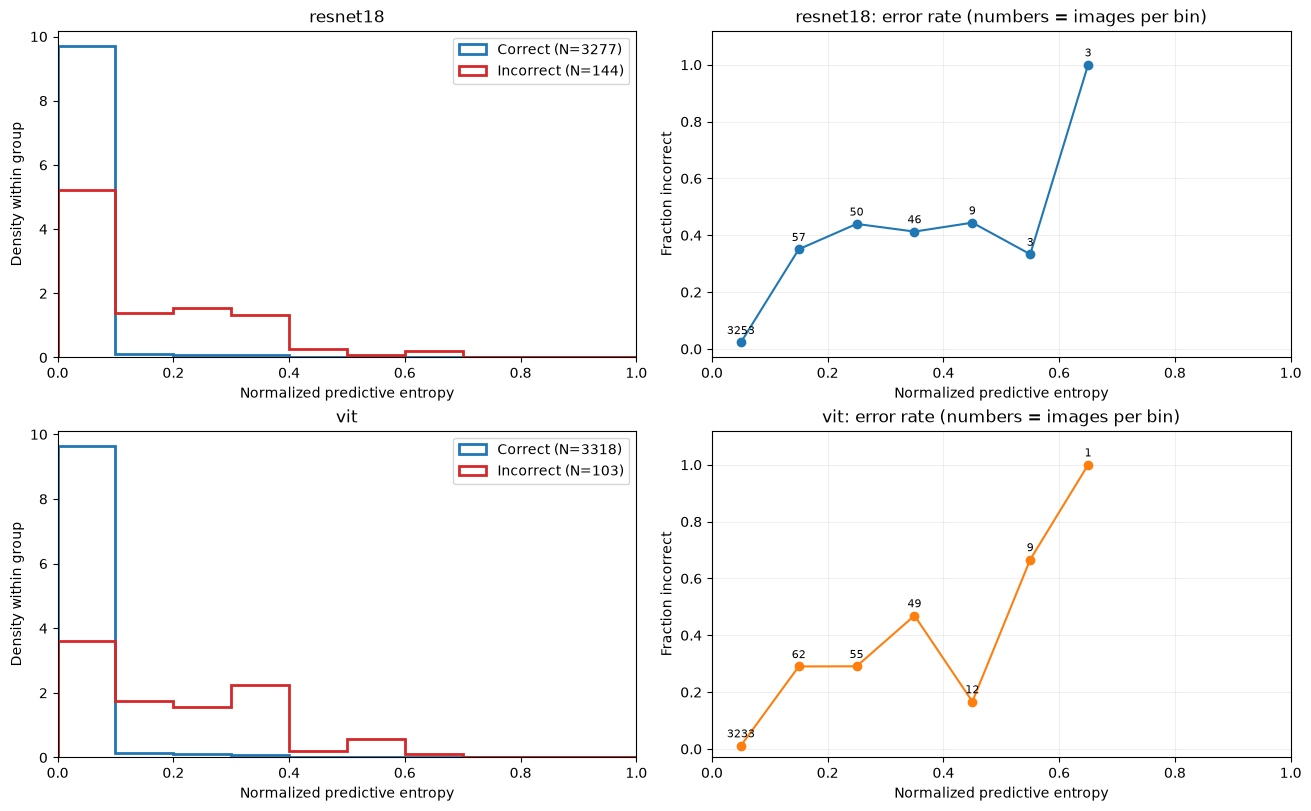

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], 'C0', 'Correct'), (~correct[m], 'C3', 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=name, xlabel='Normalized predictive entropy', ylabel='Density within group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins)
    rates = np.divide(errors, counts, out=np.full(n_bins, np.nan), where=counts > 0)
    axes[m, 1].plot(centers, rates, 'o-', color=f'C{m}')
    for x, y, n in zip(centers, rates, counts):
        if n:
            axes[m, 1].annotate(str(n), (x, y), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8)
    axes[m, 1].set(title=f'{name}: error rate (numbers = images per bin)',
                   xlabel='Normalized predictive entropy', ylabel='Fraction incorrect', xlim=(0, 1), ylim=(-0.03, 1.12))
    axes[m, 1].grid(alpha=0.2)
plt.show()

## Confidence under transformations — same 320-image stability subset; average noise repeats within each image; dashed lines show baseline

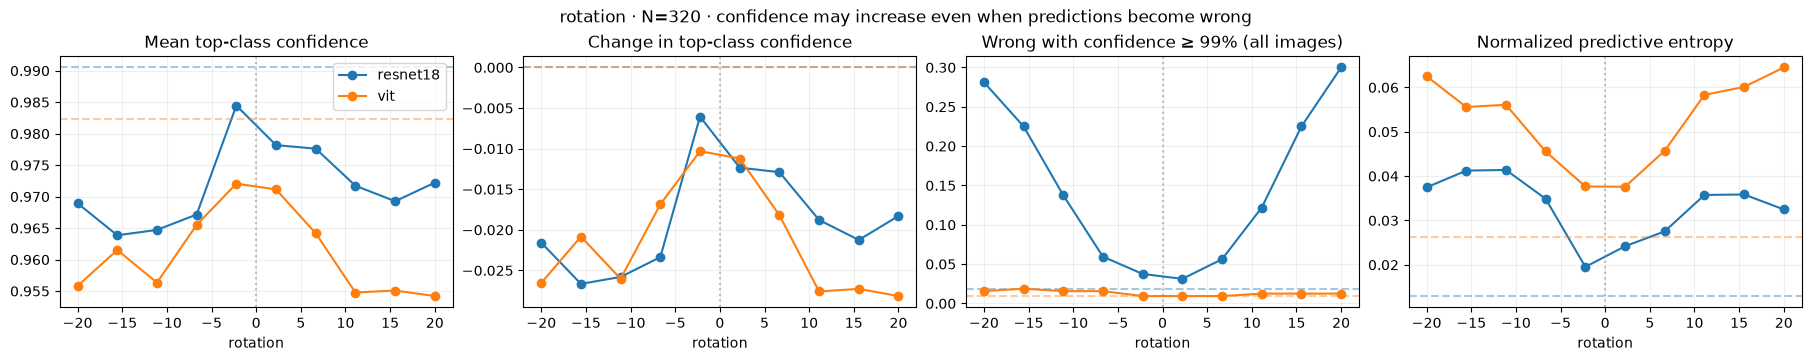

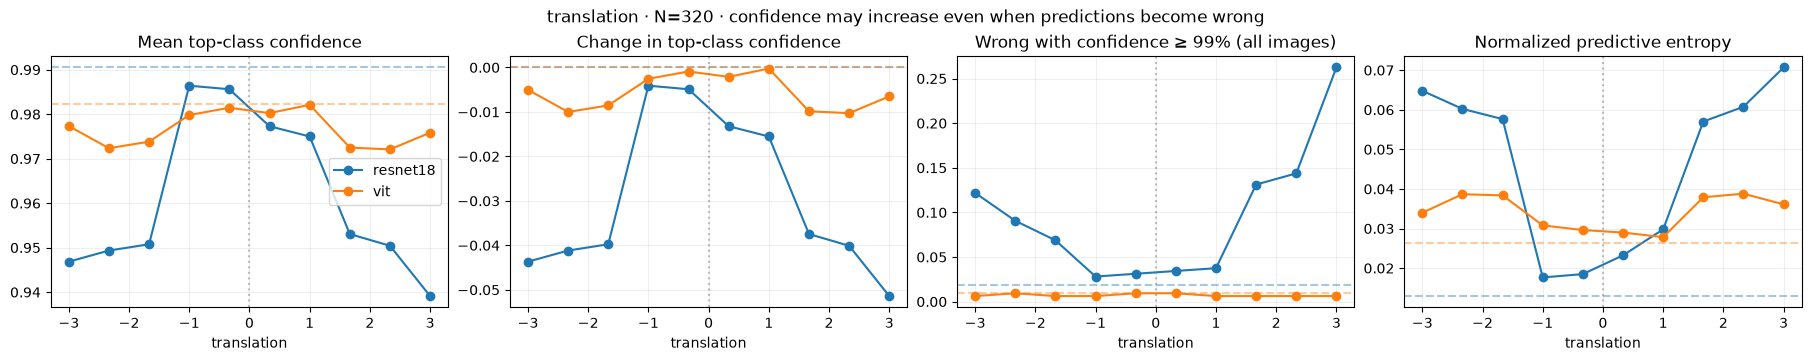

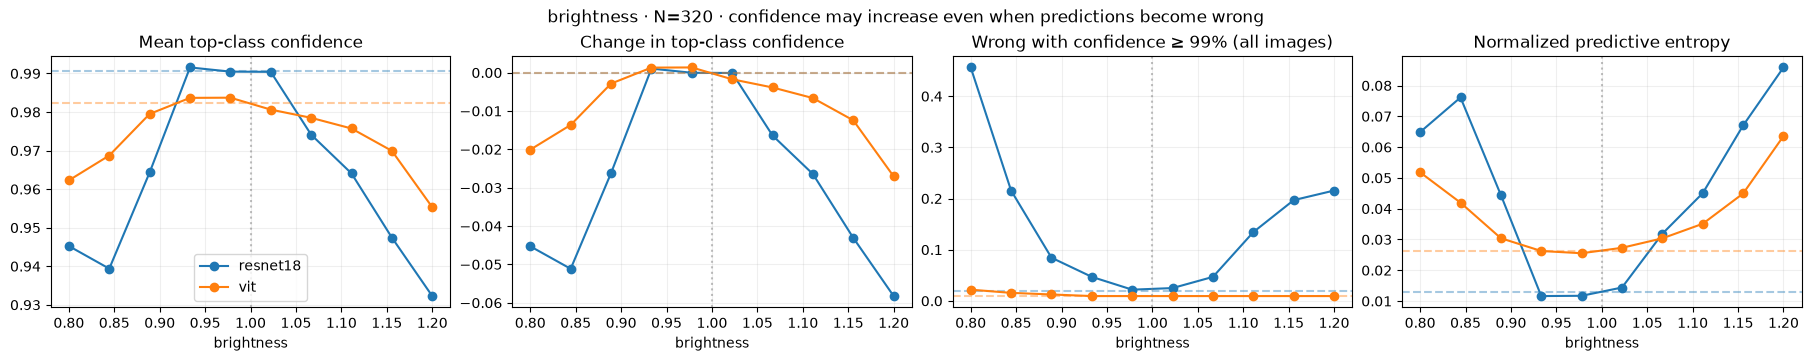

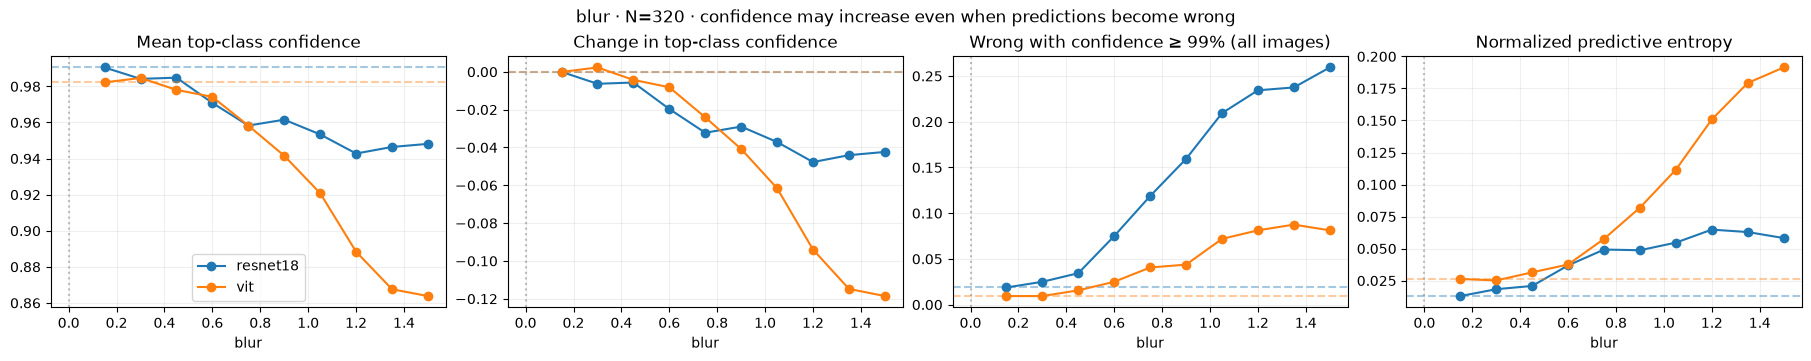

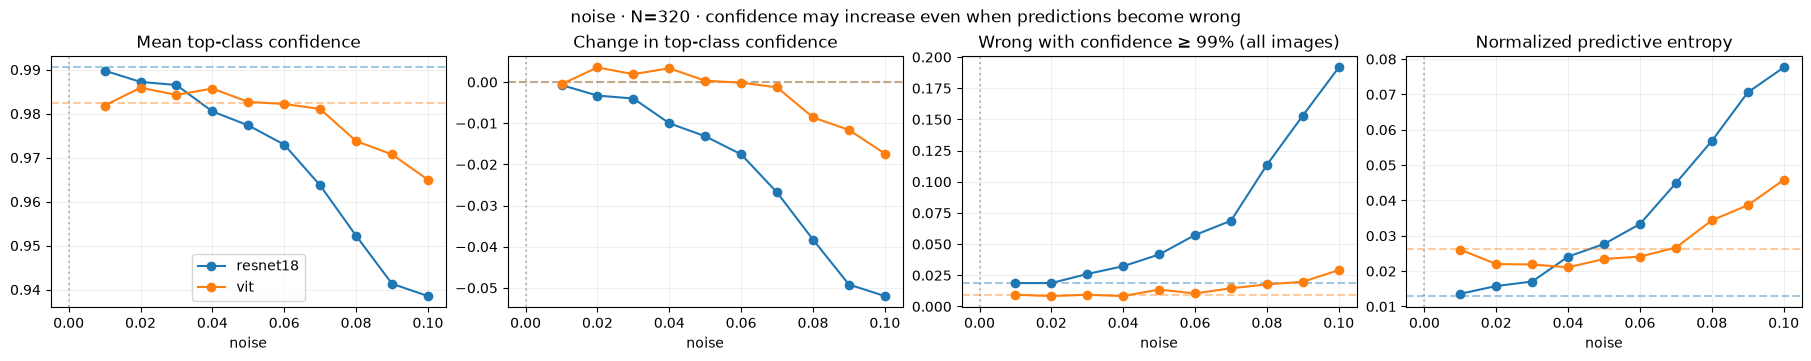

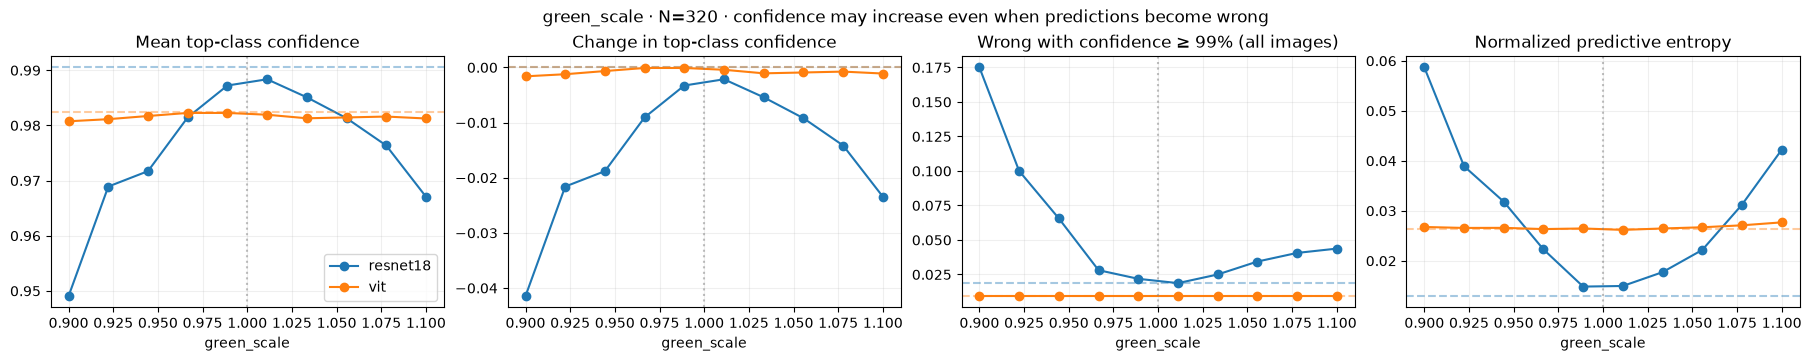

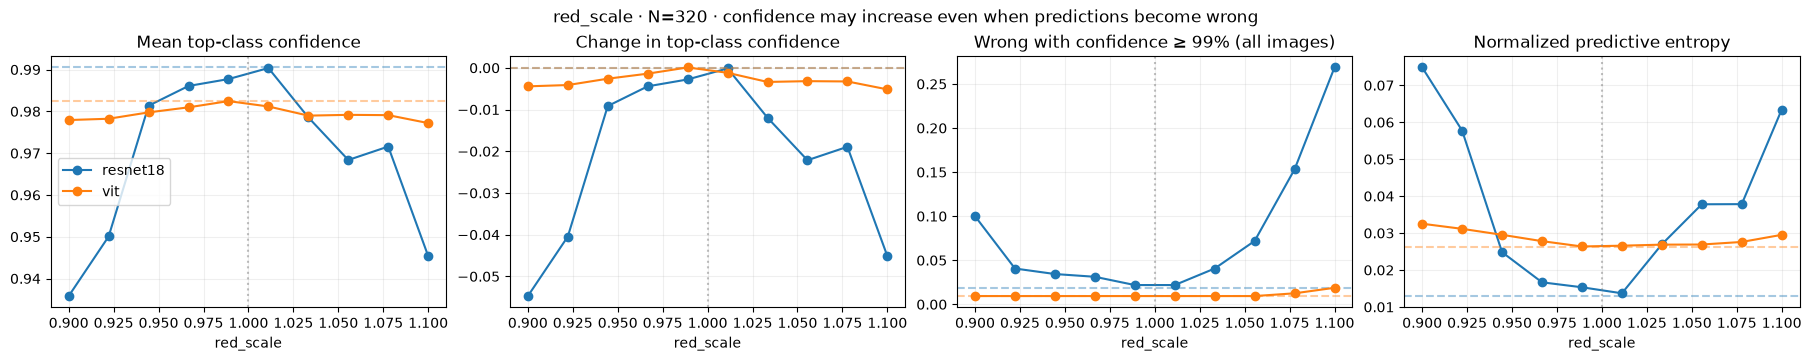

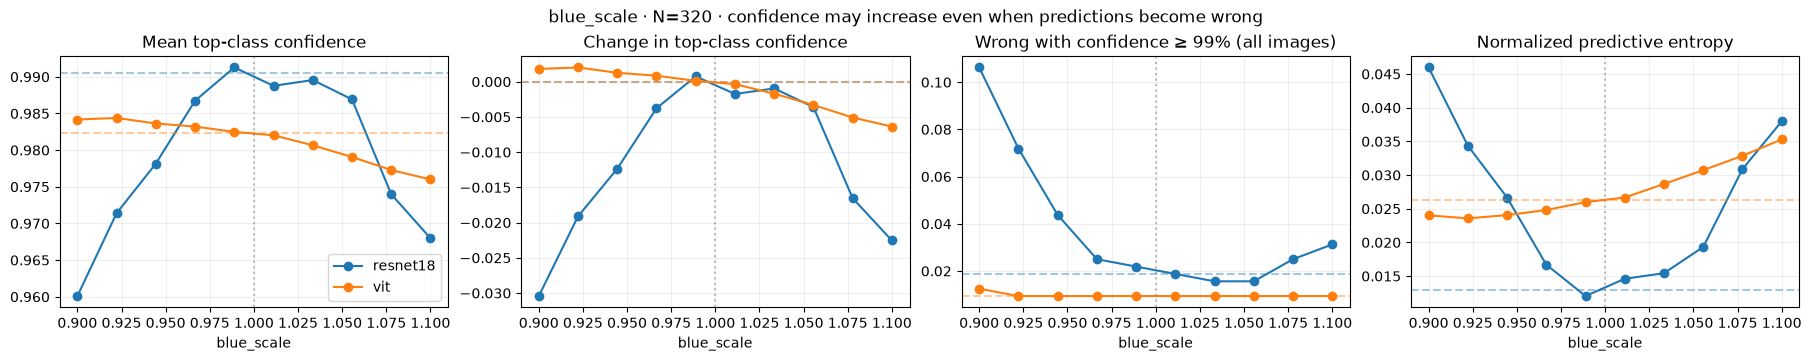

In [6]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
confidence_changes = {}
for kind, p in transformed.items():
    conf = p.max(-1)
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    metrics = {
        'Mean top-class confidence': conf.mean(axis=2),
        'Change in top-class confidence': (conf - base_confidence[:, None, None, :]).mean(axis=2),
        f'Wrong with confidence ≥ {threshold:.0%} (all images)': high_wrong.mean(axis=2),
        'Normalized predictive entropy': entropy(p).mean(axis=2),
    }
    confidence_changes[kind] = metrics
    references = [base_confidence.mean(-1), np.zeros(2), base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for ax, (title, values), original in zip(axes, metrics.items(), references):
        for m, name in enumerate(model_names):
            line, = ax.plot(levels[kind], values[m].mean(-1), 'o-', label=name)
            ax.axhline(original[m], color=line.get_color(), ls='--', alpha=0.4)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · confidence may increase even when predictions become wrong')
    plt.show()

## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [7]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold)
    print(f'{name}: {len(ids)} high-confidence errors → {path}')
    print('Test indices:', ids.tolist())

resnet18: 47 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
Test indices: [3126, 496, 1967, 1750, 3329, 340, 3373, 2908, 2935, 379, 2721, 2434, 3058, 1640, 1413, 3044, 2750, 476, 3235, 832, 849, 2942, 2251, 69, 516, 1688, 3035, 1130, 1018, 963, 873, 1629, 118, 35, 1555, 1259, 1542, 1546, 1765, 1125, 2310, 839, 271, 2917, 2036, 2735, 1108]
vit: 20 high-confidence errors → predictions\high_confidence_wrong_vit.npz
Test indices: [1462, 1750, 3126, 1629, 916, 1218, 576, 799, 476, 35, 1914, 290, 340, 432, 839, 3329, 148, 2982, 1575, 2086]


## Highest-confidence errors — first eight per model; class IDs follow data/metadata.json; all selected images are saved

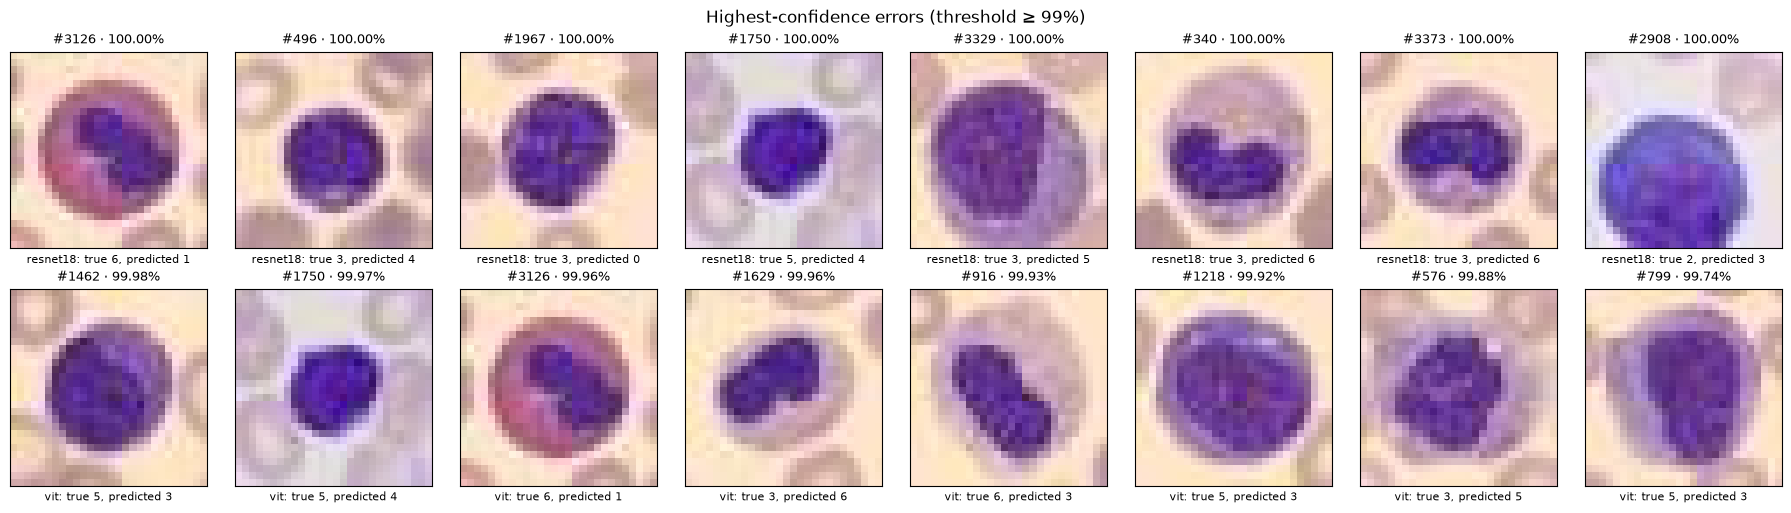

In [8]:
fig, axes = plt.subplots(2, 8, figsize=(18, 5), layout='constrained')
for m, name in enumerate(model_names):
    ids = high_confidence_wrong[name][:8]
    for ax in axes[m]:
        ax.axis('off')
    for ax, i in zip(axes[m], ids):
        ax.imshow(images[i])
        ax.set_title(f'#{i} · {confidence[m, i]:.2%}', fontsize=9)
        ax.set_xlabel(f'{name}: true {labels[i]}, predicted {predicted[m, i]}', fontsize=8)
        ax.axis('on')
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle(f'Highest-confidence errors (threshold ≥ {threshold:.0%})')
plt.show()